# Mid-Course Project

Hi there,

I’m the host of a movie reviews podcast and I’m currently making an episode about movie review aggregators.

I found this data set from Rotten Tomatoes (inside the .ipynb file that I’ve attached). Could you dig into the data and share any interesting insights that you find? My audience loves fun facts about movies.

Thank you!\
KP

## 0. Read in the Data

In [1]:
# rotten tomatoes movie data set from Maven's data playground
import pandas as pd

data_folder = r''
movies_file = r'Rotten Tomatoes Movies.csv'

df_movies = pd.read_csv(data_folder + '\\' + movies_file)
df_movies.head(3)

,movie_title,movie_info,critics_consensus,rating,genre,directors,writers,cast,in_theaters_date,on_streaming_date,runtime_in_minutes,studio_name,tomatometer_status,tomatometer_rating,tomatometer_count,audience_rating,audience_count
0,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,Though it may seem like just another Harry Pot...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,Craig Titley,"Logan Lerman, Brandon T. Jackson, Alexandra Da...",2010-02-12,2010-06-29,83.0,20th Century Fox,Rotten,49,144,53.0,254287.0
1,Please Give,Kate has a lot on her mind. There's the ethics...,Nicole Holofcener's newest might seem slight i...,R,Comedy,Nicole Holofcener,Nicole Holofcener,"Catherine Keener, Amanda Peet, Oliver Platt, R...",2010-04-30,2010-10-19,90.0,Sony Pictures Classics,Certified Fresh,86,140,64.0,11567.0
2,10,Blake Edwards' 10 stars Dudley Moore as George...,NaN,R,"Comedy, Romance",Blake Edwards,Blake Edwards,"Dudley Moore, Bo Derek, Julie Andrews, Robert ...",1979-10-05,1997-08-27,118.0,Waner Bros.,Fresh,68,22,53.0,14670.0


In [2]:
# let's work with a subset of the data for this project
df_movies = df_movies[['movie_title', 'rating', 'genre', 'in_theaters_date','runtime_in_minutes',
                 'tomatometer_rating', 'tomatometer_count', 'audience_rating', 'audience_count']]
df_movies.head()

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
0,Percy Jackson & the Olympians: The Lightning T...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",2010-02-12,83.0,49,144,53.0,254287.0
1,Please Give,R,Comedy,2010-04-30,90.0,86,140,64.0,11567.0
2,10,R,"Comedy, Romance",1979-10-05,118.0,68,22,53.0,14670.0
3,12 Angry Men (Twelve Angry Men),NR,"Classics, Drama",1957-04-13,95.0,100,51,97.0,105000.0
4,"20,000 Leagues Under The Sea",G,"Action & Adventure, Drama, Kids & Family",1954-01-01,127.0,89,27,74.0,68860.0


## Ensure the columns have the right data types

In [3]:
df_movies.dtypes

movie_title               str
rating                    str
genre                     str
in_theaters_date          str
runtime_in_minutes    float64
tomatometer_rating      int64
tomatometer_count       int64
audience_rating       float64
audience_count        float64
dtype: object

In [4]:
#Change in_teathers_date to date format
df_movies['in_theaters_date'] = pd.to_datetime(df_movies['in_theaters_date'])

In [5]:
df_movies.dtypes

movie_title                      str
rating                           str
genre                            str
in_theaters_date      datetime64[us]
runtime_in_minutes           float64
tomatometer_rating             int64
tomatometer_count              int64
audience_rating              float64
audience_count               float64
dtype: object

## 0.1. Missing Data

In [6]:
#Identify rows with missing values in any of the columns
df_movies[df_movies.isna().any(axis=1)]

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
27,A Tale of Two Pizzas,PG,Comedy,2003-11-07,82.0,38,8,NaN,NaN
58,All Quiet on the Western Front,NR,Drama,NaT,150.0,100,5,70.0,7571.0
71,The Silence,R,"Action & Adventure, Drama, Mystery & Suspense,...",NaT,104.0,50,6,38.0,374.0
75,Snow Blind,NR,"Documentary, Sports & Fitness",2006-12-01,92.0,20,5,NaN,NaN
156,The Broken,R,"Horror, Mystery & Suspense",NaT,88.0,49,39,25.0,2543.0
...,...,...,...,...,...,...,...,...,...
16552,You Got Served: Beat The World,PG-13,Drama,NaT,91.0,0,5,20.0,373.0
16555,You Might Be the Killer,NR,Horror,NaT,88.0,59,17,54.0,106.0
16584,Your Son (Tu Hijo),NR,Drama,NaT,NaN,100,5,57.0,45.0
16601,Zambezia,G,"Animation, Comedy",NaT,84.0,25,8,43.0,755.0


In [7]:
#Ensure no Null titles
df_movies.loc[df_movies['movie_title'].isna()]

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count


In [8]:
#Check if any of them did not appear in teathers or do not have the information
df_movies.loc[df_movies['in_theaters_date'].isna()]

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
58,All Quiet on the Western Front,NR,Drama,NaT,150.0,100,5,70.0,7571.0
71,The Silence,R,"Action & Adventure, Drama, Mystery & Suspense,...",NaT,104.0,50,6,38.0,374.0
156,The Broken,R,"Horror, Mystery & Suspense",NaT,88.0,49,39,25.0,2543.0
264,Three Blind Mice,PG,"Comedy, Drama",NaT,93.0,80,5,50.0,229.0
292,Avenging Angel,R,"Action & Adventure, Drama, Mystery & Suspense",NaT,94.0,33,6,26.0,1541.0
...,...,...,...,...,...,...,...,...,...
16552,You Got Served: Beat The World,PG-13,Drama,NaT,91.0,0,5,20.0,373.0
16555,You Might Be the Killer,NR,Horror,NaT,88.0,59,17,54.0,106.0
16584,Your Son (Tu Hijo),NR,Drama,NaT,NaN,100,5,57.0,45.0
16601,Zambezia,G,"Animation, Comedy",NaT,84.0,25,8,43.0,755.0


## 0.2 Check for inconsistent text or data

In [9]:
df_movies['movie_title'].value_counts().head(50)

movie_title
Hamlet                         5
Home                           5
Gloria                         4
Little Women                   4
The Mummy                      4
Robin Hood                     4
The Three Musketeers           4
Wuthering Heights              4
Alice in Wonderland            4
The Silence                    3
Hush                           3
Anna Karenina                  3
Stolen                         3
Bad Company                    3
Dracula                        3
Halloween                      3
The Hunchback of Notre Dame    3
Jack Frost                     3
King Kong                      3
Point Blank                    3
Pride and Prejudice            3
Romeo and Juliet               3
Shaft                          3
Sparkle                        3
A Star Is Born                 3
Treasure Island                3
The Trip                       3
Venom                          3
The Kid                        3
Great Expectations             

In [10]:
#No empty titles, which is good
df_movies.loc[df_movies['movie_title'] == ''] 

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count


In [11]:
#Same for Rating
df_movies['rating'].value_counts()

rating
R         6136
NR        4862
PG-13     2885
PG        2062
G          652
NC17        37
PG-13)       3
R)           1
Name: count, dtype: int64

In [12]:
#Map the wrong values
rating_mapping = {
    'R':'R',
    'NR':'NR',
    'PG-13':'PG-13',
    'PG':'PG',
    'G':'G',
    'NC17':'NC17',
    'R)':'R',
    'PG-13)':'PG-13'
}

In [13]:
df_movies['rating'] = df_movies['rating'].map(rating_mapping)

In [14]:
df_movies['rating'].value_counts()

rating
R        6137
NR       4862
PG-13    2888
PG       2062
G         652
NC17       37
Name: count, dtype: int64

In [15]:
df_movies.loc[df_movies['rating'] == '']

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count


In [16]:
#Check the same for Genre
df_movies['genre'].value_counts()

genre
Drama                                                                              1727
Comedy                                                                             1202
Comedy, Drama                                                                       819
Drama, Mystery & Suspense                                                           683
Art House & International, Drama                                                    571
                                                                                   ... 
Animation, Art House & International, Documentary                                     1
Animation, Art House & International, Drama, Science Fiction & Fantasy, Romance       1
Art House & International, Romance                                                    1
Action & Adventure, Drama, Horror, Kids & Family, Mystery & Suspense                  1
Animation, Drama, Romance                                                             1
Name: count, Length: 1080,

In [17]:
df_movies.loc[df_movies['genre'] == '']

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count


## 0.3 Check for Duplicates

In [18]:
df_movies[df_movies.duplicated(keep=False)]

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
8495,King Charles III,NR,Drama,2017-05-14,88.0,100,9,48.0,65.0
8496,King Charles III,NR,Drama,2017-05-14,88.0,100,9,48.0,65.0


In [19]:
#Drop duplicate row
df_movies = df_movies.drop_duplicates()

In [20]:
#Check that one row is still there
df_movies.loc[df_movies['movie_title'] == 'King Charles III']

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
8495,King Charles III,NR,Drama,2017-05-14,88.0,100,9,48.0,65.0


## 0.4 Check for Outliers

In [21]:
df_movies.describe()

,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
count,15822,16482.000000,16637.000000,16637.000000,16385.00000,1.638500e+04
mean,1999-10-24 12:27:23.686006,102.392367,60.464146,56.609966,60.47159,1.524890e+05
min,1914-06-01 00:00:00,1.000000,0.000000,5.000000,0.00000,5.000000e+00
25%,1993-03-27 12:00:00,90.000000,38.000000,12.000000,45.00000,8.650000e+02
50%,2006-08-04 00:00:00,99.000000,66.000000,28.000000,62.00000,4.877000e+03
75%,2013-06-28 00:00:00,111.000000,86.000000,76.000000,77.00000,2.876500e+04
max,2019-12-07 00:00:00,2000.000000,100.000000,497.000000,100.00000,3.579764e+07
std,NaN,25.028519,28.586446,66.384769,20.46276,1.817791e+06


In [22]:
df_movies.loc[df_movies['runtime_in_minutes'] > 1000]

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
13539,Terror Tract,R,"Comedy, Horror, Mystery & Suspense",2000-10-18,2000.0,60,5,35.0,586.0


<Axes: xlabel='runtime_in_minutes', ylabel='Count'>

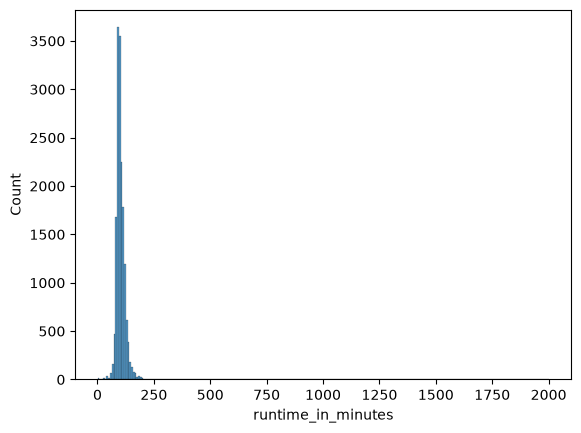

In [23]:
import seaborn as sns
sns.histplot(df_movies['runtime_in_minutes'])

## 1. Explore the Data

How many movies are in this data set?

In [24]:
#Counts the unique values, if you use unique instead it shows it all in a list
df_movies['movie_title'].nunique()

16106

Filter the data to only include movies that came out in 2010 or later. How many movies are in this new data set?

In [25]:
df_movies = df_movies.loc[df_movies['in_theaters_date'].dt.year >= 2010]

In [26]:
df_movies.head(5)

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
0,Percy Jackson & the Olympians: The Lightning T...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",2010-02-12,83.0,49,144,53.0,254287.0
1,Please Give,R,Comedy,2010-04-30,90.0,86,140,64.0,11567.0
97,Fireflies in the Garden,R,Drama,2011-10-14,98.0,22,54,45.0,45150.0
130,The Oxford Murders,R,"Art House & International, Drama, Horror, Myst...",2010-08-06,110.0,9,11,33.0,14548.0
155,Priest,PG-13,"Action & Adventure, Horror, Mystery & Suspense...",2011-05-13,83.0,15,99,46.0,86566.0


Find the highest rated movies according to both critics (*tomatometer_rating*) and the general audience (*audience_rating*).

In [27]:
df_movies = df_movies.sort_values(by=['tomatometer_rating', 'audience_rating'], ascending=False)

These top movies seem to have very few critics and audience members writing the reviews. We want to look at only the most popular movies. Filter the movies data set to only include movies that have 100k+ audience ratings. How many movies are in this data set?

In [28]:
df_movies = df_movies.loc[df_movies['audience_count'] >= 100000]

In [29]:
df_movies.head(5)

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
7558,How to Train Your Dragon,PG,"Animation, Kids & Family, Science Fiction & Fa...",2010-03-26,98.0,99,208,91.0,312342.0
7925,Inside Out,PG,"Animation, Kids & Family",2015-06-19,94.0,98,357,89.0,136125.0
15416,Toy Story 3,G,"Animation, Comedy, Kids & Family",2010-06-18,103.0,98,305,89.0,606931.0
16634,Zootopia,PG,"Action & Adventure, Animation, Comedy",2016-03-04,108.0,97,279,92.0,100946.0
9355,Mad Max: Fury Road,R,"Action & Adventure, Science Fiction & Fantasy",2015-05-15,120.0,97,410,85.0,127428.0


Find the highest rated **popular** movies according to both critics (*tomatometer_rating*) and the general audience (*audience_rating*).

In [30]:
df_movies.sort_values(by=['tomatometer_rating', 'audience_rating'], ascending=False)

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
7558,How to Train Your Dragon,PG,"Animation, Kids & Family, Science Fiction & Fa...",2010-03-26,98.0,99,208,91.0,312342.0
7925,Inside Out,PG,"Animation, Kids & Family",2015-06-19,94.0,98,357,89.0,136125.0
15416,Toy Story 3,G,"Animation, Comedy, Kids & Family",2010-06-18,103.0,98,305,89.0,606931.0
16634,Zootopia,PG,"Action & Adventure, Animation, Comedy",2016-03-04,108.0,97,279,92.0,100946.0
9355,Mad Max: Fury Road,R,"Action & Adventure, Science Fiction & Fantasy",2015-05-15,120.0,97,410,85.0,127428.0
...,...,...,...,...,...,...,...,...,...
5945,Fantastic Four,PG-13,Action & Adventure,2015-08-07,100.0,9,252,18.0,137562.0
6942,Grown Ups 2,PG-13,Comedy,2013-07-12,101.0,7,112,53.0,180859.0
3387,"Big Mommas: Like Father, Like Son",PG-13,Comedy,2011-02-18,107.0,5,60,58.0,132093.0
8714,The Last Airbender,PG,"Action & Adventure, Kids & Family, Science Fic...",2010-07-01,103.0,5,189,30.0,321915.0


A lot of these popular movies seem to have a PG or PG-13 rating. How many movies fall under each type of rating?

*Use this popular movies data set going forward in this notebook.*

In [31]:
df_movies['rating'].value_counts()

rating
PG-13    160
R        100
PG        51
G          5
Name: count, dtype: int64

What is the average audience rating for each movie rating type? Which rating type is most highly rated?

In [32]:
round(df_movies.groupby('rating')['audience_rating'].mean(), 2).sort_values(ascending=False)

rating
PG-13    67.29
PG       66.82
G        66.20
R        63.01
Name: audience_rating, dtype: float64

In [33]:
df_movies.head(5)

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
7558,How to Train Your Dragon,PG,"Animation, Kids & Family, Science Fiction & Fa...",2010-03-26,98.0,99,208,91.0,312342.0
7925,Inside Out,PG,"Animation, Kids & Family",2015-06-19,94.0,98,357,89.0,136125.0
15416,Toy Story 3,G,"Animation, Comedy, Kids & Family",2010-06-18,103.0,98,305,89.0,606931.0
16634,Zootopia,PG,"Action & Adventure, Animation, Comedy",2016-03-04,108.0,97,279,92.0,100946.0
9355,Mad Max: Fury Road,R,"Action & Adventure, Science Fiction & Fantasy",2015-05-15,120.0,97,410,85.0,127428.0


## 2. Create New Columns

Create a column in the DataFrame called 'Animation' and return a 1 if a movie is an 'Animation' movie and 0 otherwise. Do the same for *Action & Adventure* and *Comedy*.

*Hint: use np.where and str.contains*

In [34]:
import numpy as np

In [35]:
df_movies.head()

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
7558,How to Train Your Dragon,PG,"Animation, Kids & Family, Science Fiction & Fa...",2010-03-26,98.0,99,208,91.0,312342.0
7925,Inside Out,PG,"Animation, Kids & Family",2015-06-19,94.0,98,357,89.0,136125.0
15416,Toy Story 3,G,"Animation, Comedy, Kids & Family",2010-06-18,103.0,98,305,89.0,606931.0
16634,Zootopia,PG,"Action & Adventure, Animation, Comedy",2016-03-04,108.0,97,279,92.0,100946.0
9355,Mad Max: Fury Road,R,"Action & Adventure, Science Fiction & Fantasy",2015-05-15,120.0,97,410,85.0,127428.0


In [36]:
#Animation column
df_movies['animation'] = np.where(df_movies['genre'].str.lower().str.contains('animation'), 1, 0).copy()

In [37]:
#Action & Adventure column
df_movies['action_&_adventure'] = np.where(df_movies['genre'].str.lower().str.contains('action & adventure'), 1, 0).copy()

In [38]:
#Comedy column
df_movies['comedy'] = np.where(df_movies['genre'].str.lower().str.contains('comedy'), 1, 0).copy()

In [39]:
df_movies.head(5)

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count,animation,action_&_adventure,comedy
7558,How to Train Your Dragon,PG,"Animation, Kids & Family, Science Fiction & Fa...",2010-03-26,98.0,99,208,91.0,312342.0,1,0,0
7925,Inside Out,PG,"Animation, Kids & Family",2015-06-19,94.0,98,357,89.0,136125.0,1,0,0
15416,Toy Story 3,G,"Animation, Comedy, Kids & Family",2010-06-18,103.0,98,305,89.0,606931.0,1,0,1
16634,Zootopia,PG,"Action & Adventure, Animation, Comedy",2016-03-04,108.0,97,279,92.0,100946.0,1,1,1
9355,Mad Max: Fury Road,R,"Action & Adventure, Science Fiction & Fantasy",2015-05-15,120.0,97,410,85.0,127428.0,0,1,0


Create a table where each row is a rating, each column is a genre and each value is the number of movies of that particular rating and genre. What insights do you gather?

In [41]:
#Create a pivot table
#df_movies.pivot_table(index='rating', columns='genre', values='movie_title', aggfunc='count')

#Use Groupby to get a clearer picture
df_movies.groupby('rating')[['animation', 'action_&_adventure', 'comedy']].sum()

,animation,action_&_adventure,comedy
rating,,,
G,5,3,5
PG,26,27,29
PG-13,0,102,35
R,0,41,35


In [45]:
#Quick check, make sure it's right
df_movies.loc[(df_movies['rating'] == 'G') & (df_movies['genre'] == 'Action & Adventure, Animation, Comedy, Kids & Family')]

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count,animation,action_&_adventure,comedy
4119,Cars 2,G,"Action & Adventure, Animation, Comedy, Kids & ...",2011-06-24,112.0,39,215,49.0,103439.0,1,1,1


Find the average critic and audience rating for an Animation movie vs a non-Animation movie. Do the same for Action & Adventure and Comedy. What insights do you gather?

In [51]:
#Avg Critic and Audience rating for Animation vs Non Animation
round(df_movies.groupby('animation')[['tomatometer_rating', 'audience_rating']].mean(), 2)

,tomatometer_rating,audience_rating
animation,,
0,58.34,64.83
1,75.26,75.16


In [55]:
#Avg Critic and Audience rating for Action & Adventure
round(df_movies.groupby('action_&_adventure')[['tomatometer_rating', 'audience_rating']].mean(), 2)

,tomatometer_rating,audience_rating
action_&_adventure,,
0,59.11,65.39
1,60.73,66.22


In [56]:
#Avg Critic and Audience rating for Comedy
round(df_movies.groupby('comedy')[['tomatometer_rating', 'audience_rating']].mean(), 2)

,tomatometer_rating,audience_rating
comedy,,
0,62.17,67.35
1,55.58,62.77


## 3. Visualize the Data

Create a pair plot from the popular movies DataFrame.

In [58]:
import seaborn as sns

In [43]:
df_movies[['runtime_in_minutes', 'tomatometer_rating', 'tomatometer_count', 'audience_rating', 'audience_count']].corr()

,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count
runtime_in_minutes,1.000000,0.261717,0.581755,0.396743,0.225332
tomatometer_rating,0.261717,1.000000,0.581145,0.798293,0.098334
tomatometer_count,0.581755,0.581145,1.000000,0.528196,0.192638
audience_rating,0.396743,0.798293,0.528196,1.000000,0.158131
audience_count,0.225332,0.098334,0.192638,0.158131,1.000000


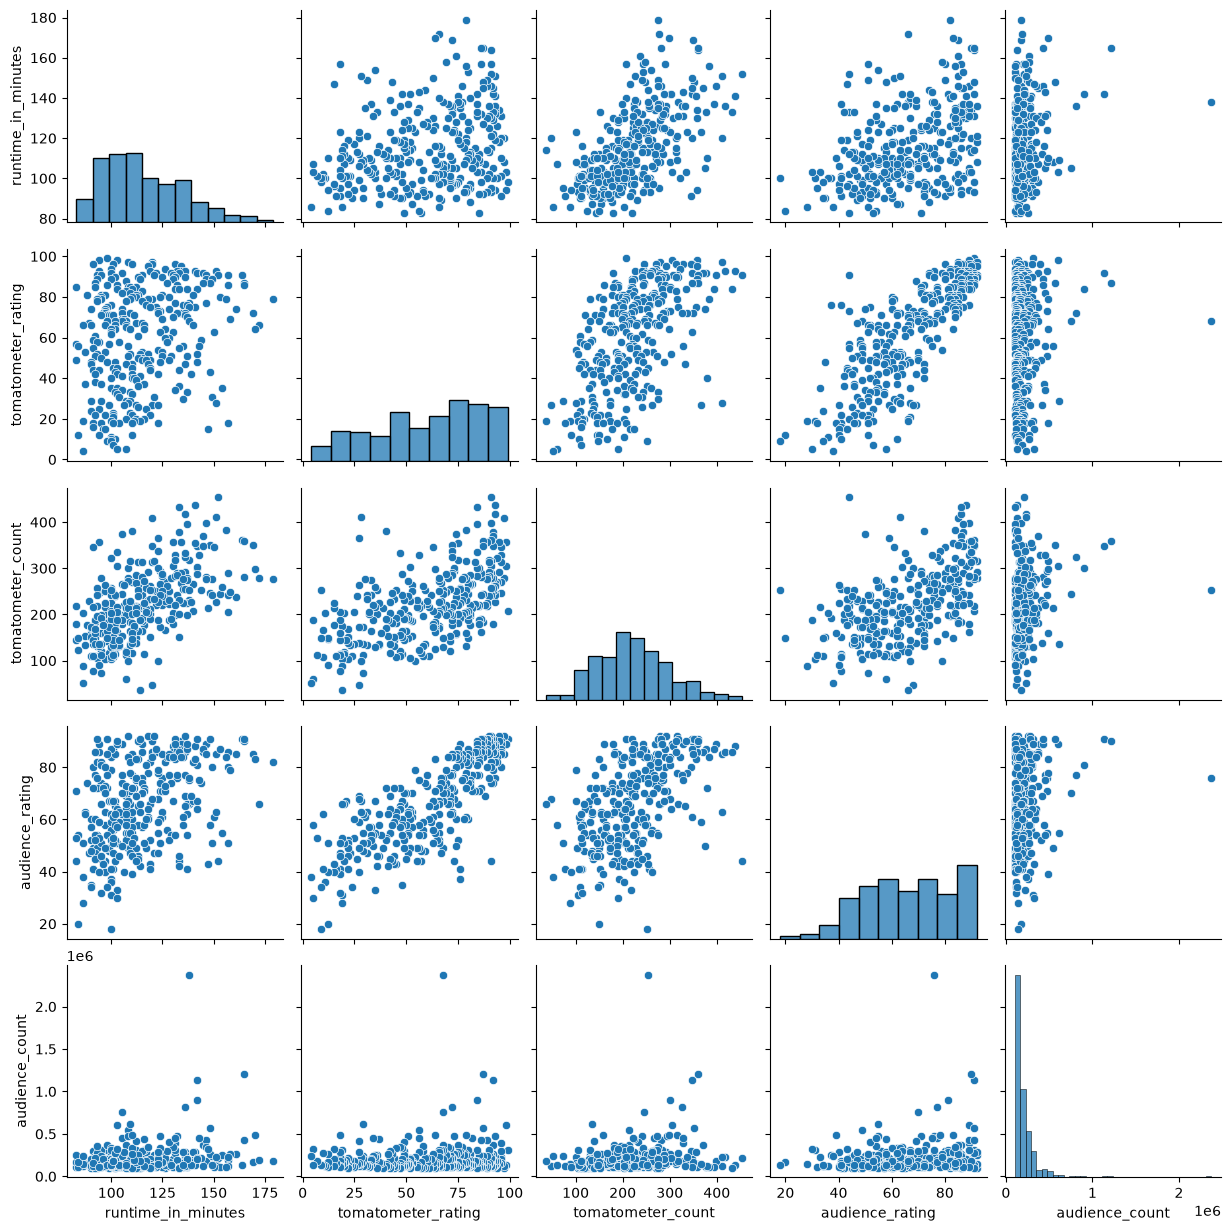

In [44]:
#Remove the 3 last columns from the pairplot as they don't add much
sns.pairplot(df_movies.iloc[:,:-3])

What insights can you gather from this pair plot?
* How do the critic ratings (tomatometer_rating) compare with the audience ratings (compare the histograms)?
* What are some surprising findings about the run times of movies compared with other fields (look at the scatter plots)?
* What is the most popular movie by far in terms of the number of audience ratings?

In [ ]:
#Both are right skewed, there is a high correlation between them, audience_ratings tend to have higher positives
#Runtime of movies tend to be more spread out, although with a high correlation with the others

In [45]:
#Row with the most popular movie based on number of audience ratings
df_movies.nlargest(3, 'audience_count')

,movie_title,rating,genre,in_theaters_date,runtime_in_minutes,tomatometer_rating,tomatometer_count,audience_rating,audience_count,animation,action_&_adventure,comedy
1646,Shutter Island,R,"Action & Adventure, Drama, Mystery & Suspense",2010-02-19,138.0,68,253,76.0,2373625.0,0,1,0
13936,The Dark Knight Rises,PG-13,"Action & Adventure, Drama, Mystery & Suspense",2012-07-20,165.0,87,360,90.0,1210957.0,0,1,0
9581,Marvel's The Avengers,PG-13,"Action & Adventure, Science Fiction & Fantasy",2012-05-04,142.0,92,348,91.0,1134955.0,0,1,0
